In [9]:
options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

In [10]:
library('tidymodels')

gss <- read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss |> glimpse()

Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”


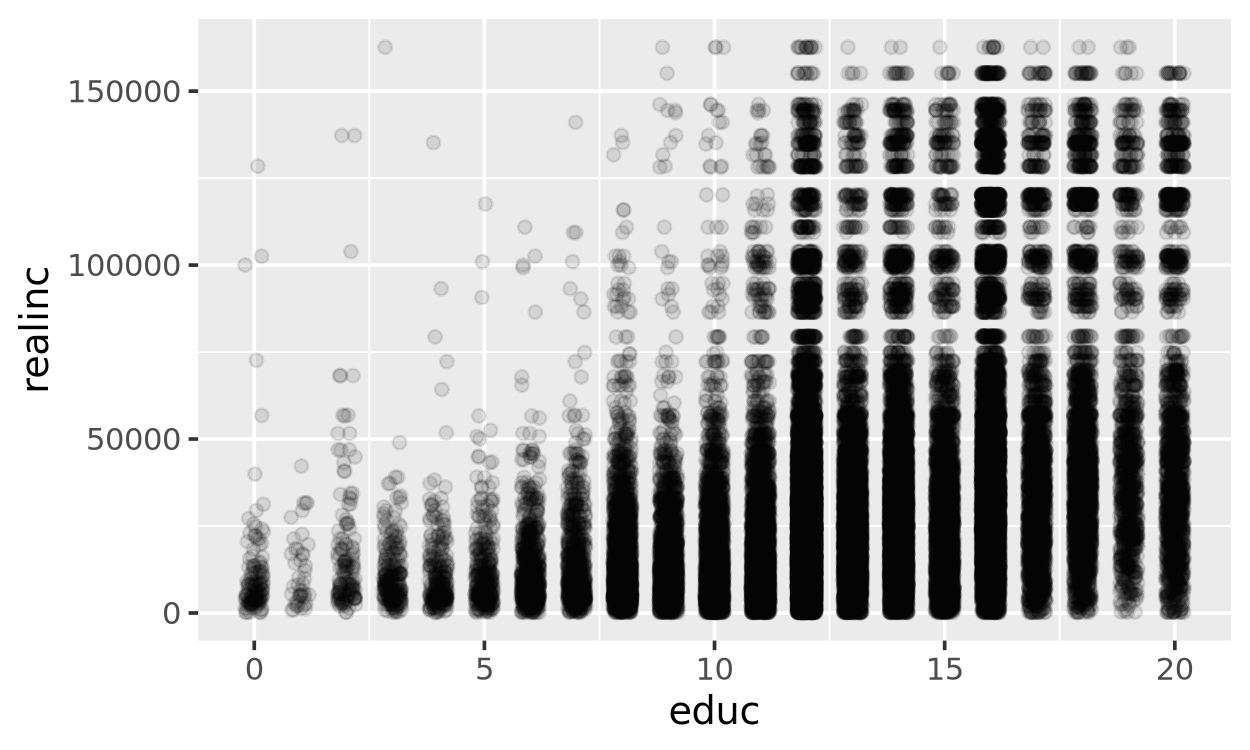

In [11]:
ggplot(gss, aes(x = educ, y = realinc)) +
    geom_point(alpha = 0.1, position = position_jitter(width = 0.2, height = 0))

In [12]:
# predictor
# feature
# regressor 

In [13]:
set.seed(512)

n_combos <- 250

param_grid <- tibble(
  combo     = 1:n_combos,
  intercept = runif(n_combos, 0, 40000),
  slope     = runif(n_combos, -1000, 5000)
)

param_grid |> head()

  combo intercept slope    
1 1     15413.309 1239.2087
2 2      5354.666  169.2174
3 3     18270.370 4682.2865
4 4     37297.365 2279.7293
5 5     25749.956 1865.6305
6 6      7894.540 3629.1521

Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


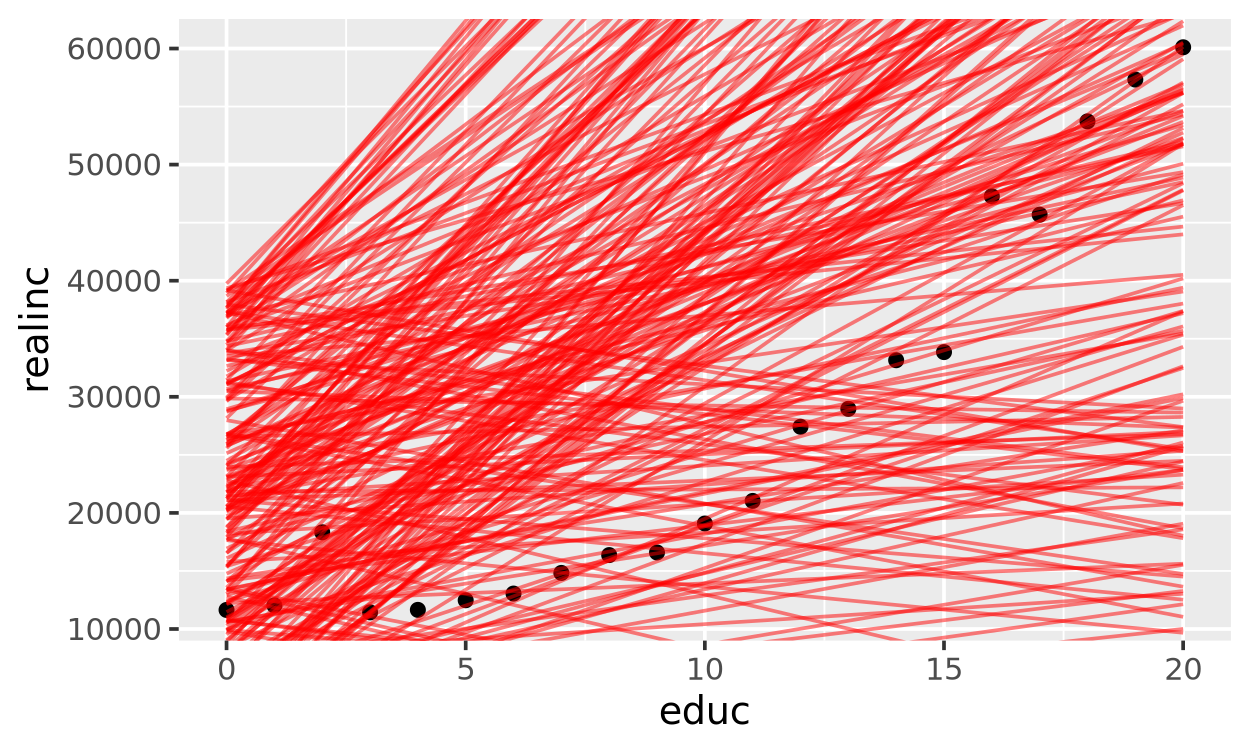

In [14]:
educ_seq <- seq(min(gss$educ, na.rm = TRUE),
                max(gss$educ, na.rm = TRUE),
                length.out = 100)

model_lines <- param_grid |>
  expand_grid(educ = educ_seq) |>
  mutate(realinc = intercept + slope * educ)

educ_means <- gss |>
  group_by(educ) |>
  summarise(realinc = mean(realinc, na.rm = TRUE))

ggplot(educ_means, aes(x = educ, y = realinc)) +
  geom_point() +
  geom_line(data = model_lines, aes(group = combo), colour = "red", alpha = 0.5) +
  coord_cartesian(ylim = range(educ_means$realinc))

Steps for creating a model:

1. pick the model form: a linear model

$$\text{realinc} = \text{intercept} + \text{slope} \cdot \text{educ}$$

2. design a way to evaluate different model parameters
3. optimize out parameter values 

In [24]:
rmse_for_params <- function(intercept, slope, data = gss) {
  pred <- intercept + slope * data$educ
  sqrt(mean((data$realinc - pred)^2, na.rm = TRUE))
} 

Warning message:
“Removed 250 rows containing missing values or values outside the scale range (`geom_point()`).”


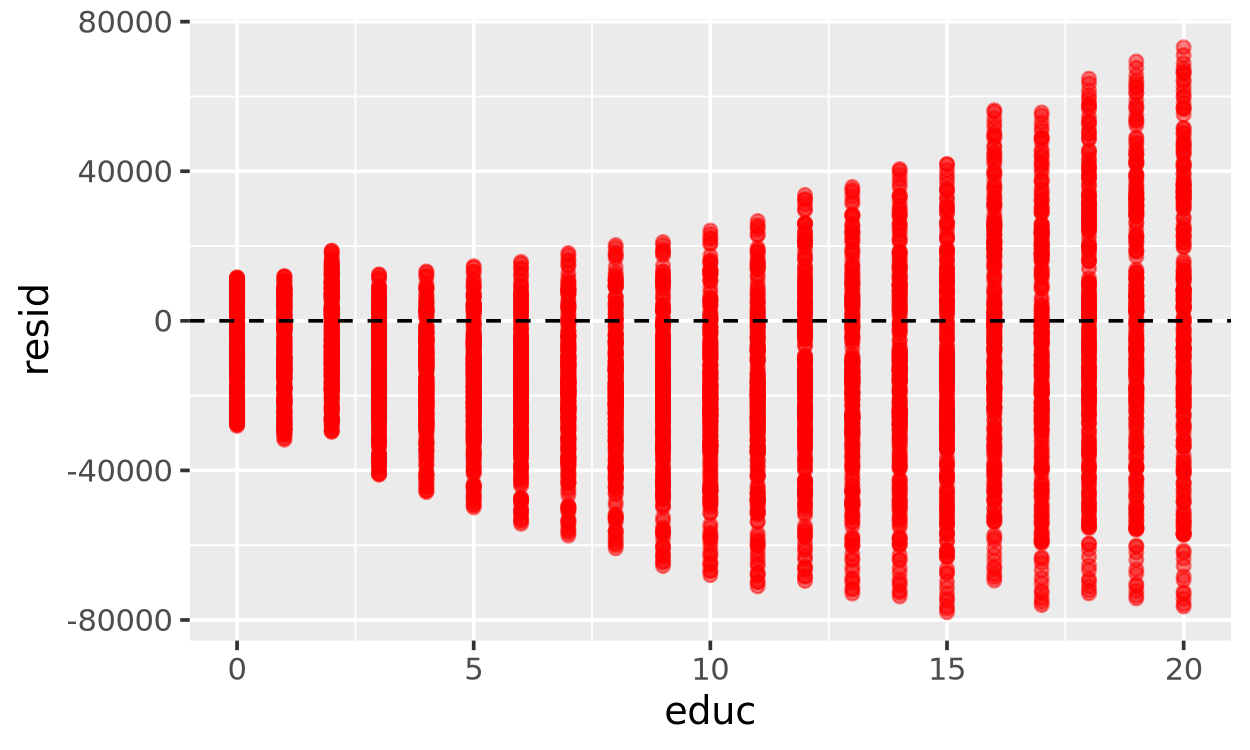

In [16]:
resid_means <- param_grid |>
  expand_grid(educ = educ_means$educ) |>
  left_join(educ_means, by = "educ") |>
  mutate(pred  = intercept + slope * educ,
         resid = realinc - pred)

ggplot(resid_means, aes(x = educ, y = resid, group = combo)) +
  geom_point(colour = "red", alpha = 0.5) +
  geom_hline(yintercept = 0, linetype = "dashed")

In [17]:
param_grid <- param_grid |>
  mutate(rmse = map2_dbl(intercept, slope, rmse_for_params))

param_grid |> head()

  combo intercept slope     rmse    
1 1     15413.309 1239.2087 29258.17
2 2      5354.666  169.2174 39248.09
3 3     18270.370 4682.2865 55223.22
4 4     37297.365 2279.7293 44980.77
5 5     25749.956 1865.6305 33828.44
6 6      7894.540 3629.1521 36509.59

Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


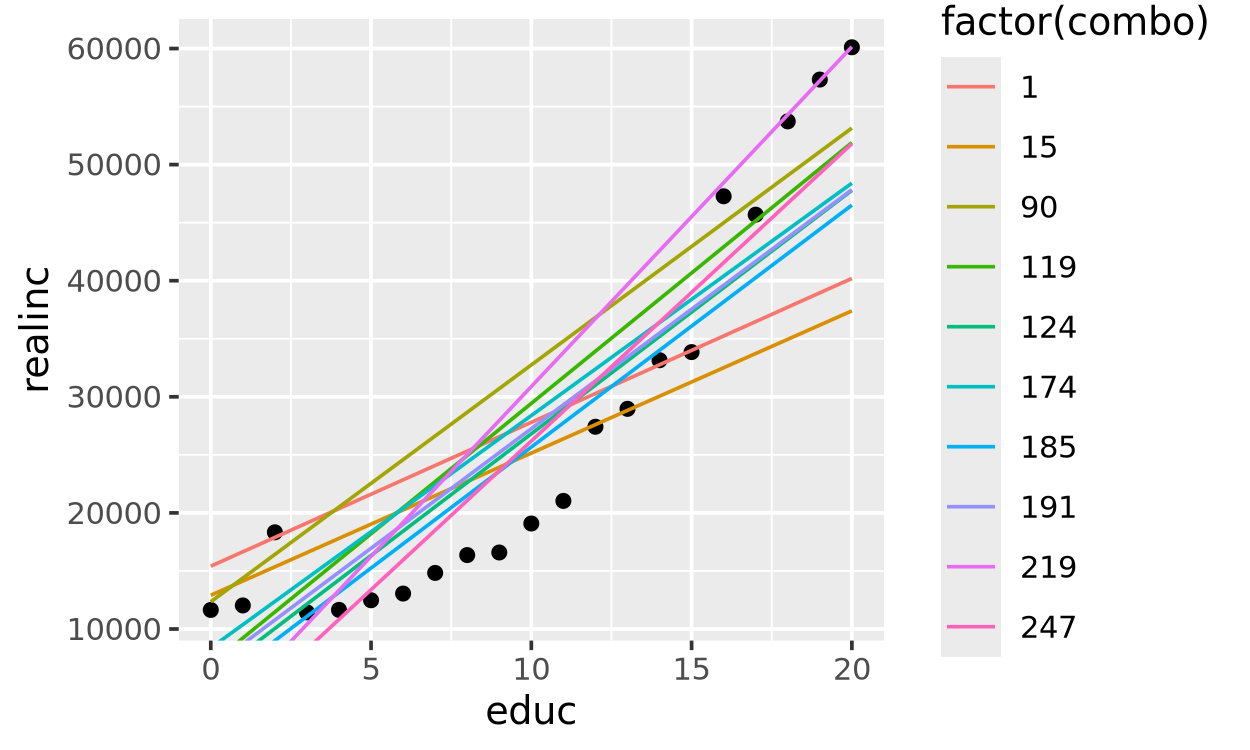

In [18]:
educ_seq <- seq(min(gss$educ, na.rm = TRUE),
                max(gss$educ, na.rm = TRUE),
                length.out = 100)

best_models <- param_grid |>
  slice_min(rmse, n = 10)

model_lines <- best_models |>
  expand_grid(educ = educ_seq) |>
  mutate(realinc = intercept + slope * educ)

educ_means <- gss |>
  group_by(educ) |>
  summarise(realinc = mean(realinc, na.rm = TRUE))

ggplot(educ_means, aes(x = educ, y = realinc)) +
  geom_point() +
  geom_line(data = model_lines, aes(group = combo, colour = factor(combo))) +
  coord_cartesian(ylim = range(educ_means$realinc))

In [ ]:
# what values for slope and intercept minimize RMSE?

## Algorithm - Random Search
1. give me some random slope and intercept values
2. calculate RMSE for all combos
3. find the best line
4. now we have a slope and intercept for the model

## Algorithm - Grid Search
1. give me some grid of slope and intercept values
2. calculate RMSE for all combos
3. find the best line
4. now we have a slope and intercept for the model

In [20]:
expand_grid(
    a = c(1,2,3),
    b = c('a','b','c')
) |> display()

a,b
<dbl>,<chr>
1,a
1,b
1,c
2,a
2,b
2,c
3,a
3,b
3,c


In [32]:
grid <- expand_grid(
    intercept = seq(-25000, -5000, length = 25),
    slope = seq(2500, 4500, length = 25)
)  |>
    mutate(dist = map2_dbl(intercept, slope, rmse_for_params))

grid |> head()

  intercept slope    dist    
1 -25000    2500.000 37702.02
2 -25000    2583.333 36970.70
3 -25000    2666.667 36259.68
4 -25000    2750.000 35570.16
5 -25000    2833.333 34903.42
6 -25000    2916.667 34260.79

In [33]:
grid |> slice_min(dist, n =5)

  intercept slope    dist    
1 -13333.33 3500.000 28301.22
2 -15833.33 3666.667 28301.81
3 -14166.67 3583.333 28302.72
4 -15000.00 3583.333 28303.15
5 -12500.00 3416.667 28304.59

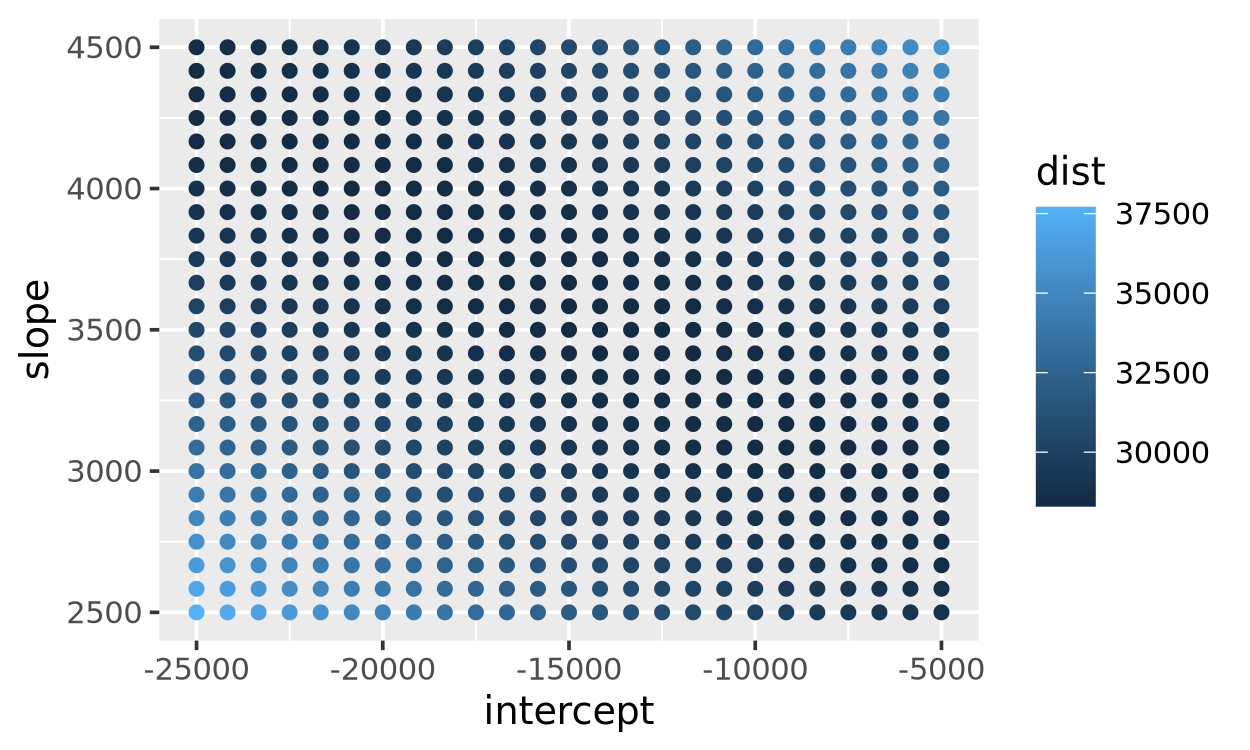

In [34]:
ggplot(grid, aes(x = intercept, y = slope, color = dist)) + geom_point()

In [ ]:
gss |> 
    group_by(educ) |>
    summarize(realinc=mean(realinc, na.rm = TRUE)) |>
    ggplot( )

## Tidymodels

In [35]:
mod = linear_reg()

mod

Linear Regression Model Specification (regression)

Computational engine: lm 


In [38]:
mod_fit = mod |> fit(realinc ~ educ, data =  gss) # "fit" means find the optimal parameter values
                                                  # formula syntax

mod_fit

parsnip model object


Call:
stats::lm(formula = realinc ~ educ, data = data)

Coefficients:
(Intercept)         educ  
     -14472         3576  


## Marginal effect

The marginal effect of education on income is $3,576

Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”
Warning message:
“Removed 286 rows containing missing values or values outside the scale range (`geom_line()`).”


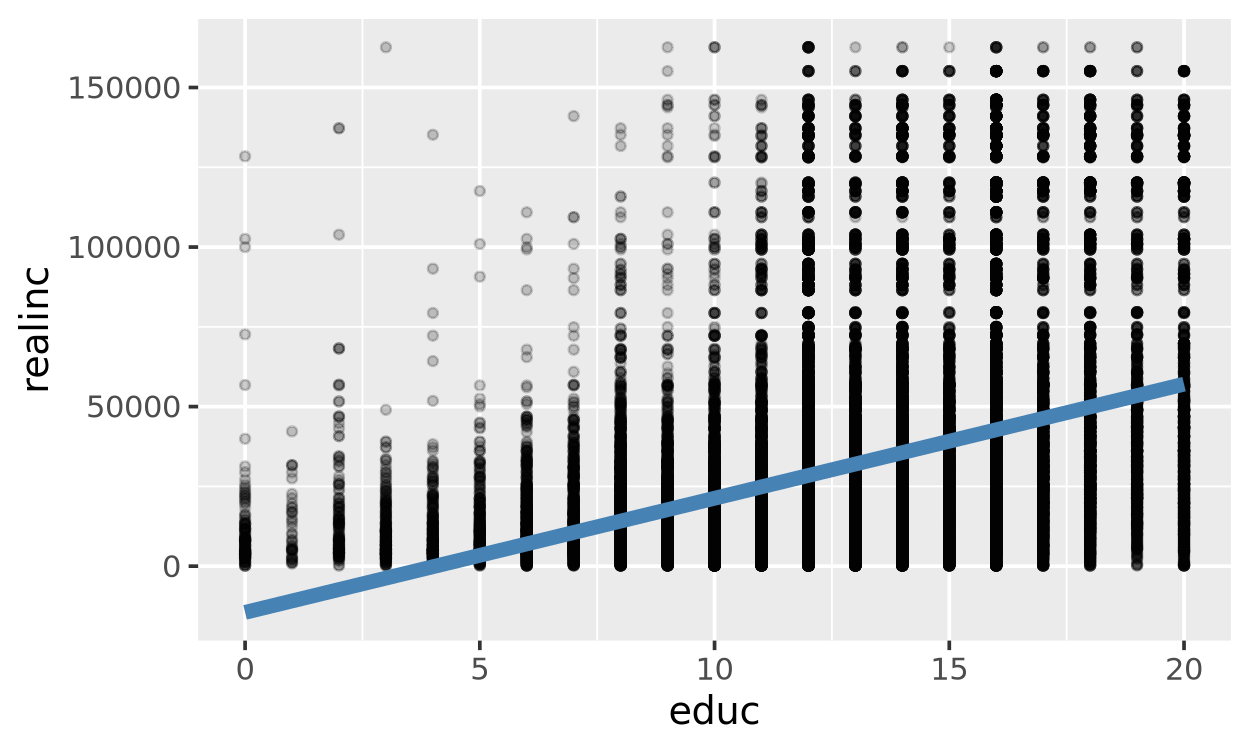

In [54]:
predict(mod_fit, gss) |> bind_cols(gss) |>
ggplot(aes(x = educ, y = realinc)) + 
    geom_point(alpha = .2, size =1) +
    geom_line(aes(y = .pred), color = 'steelblue', linewidth = 2)

Warning message:
“Removed 286 rows containing missing values or values outside the scale range (`geom_line()`).”


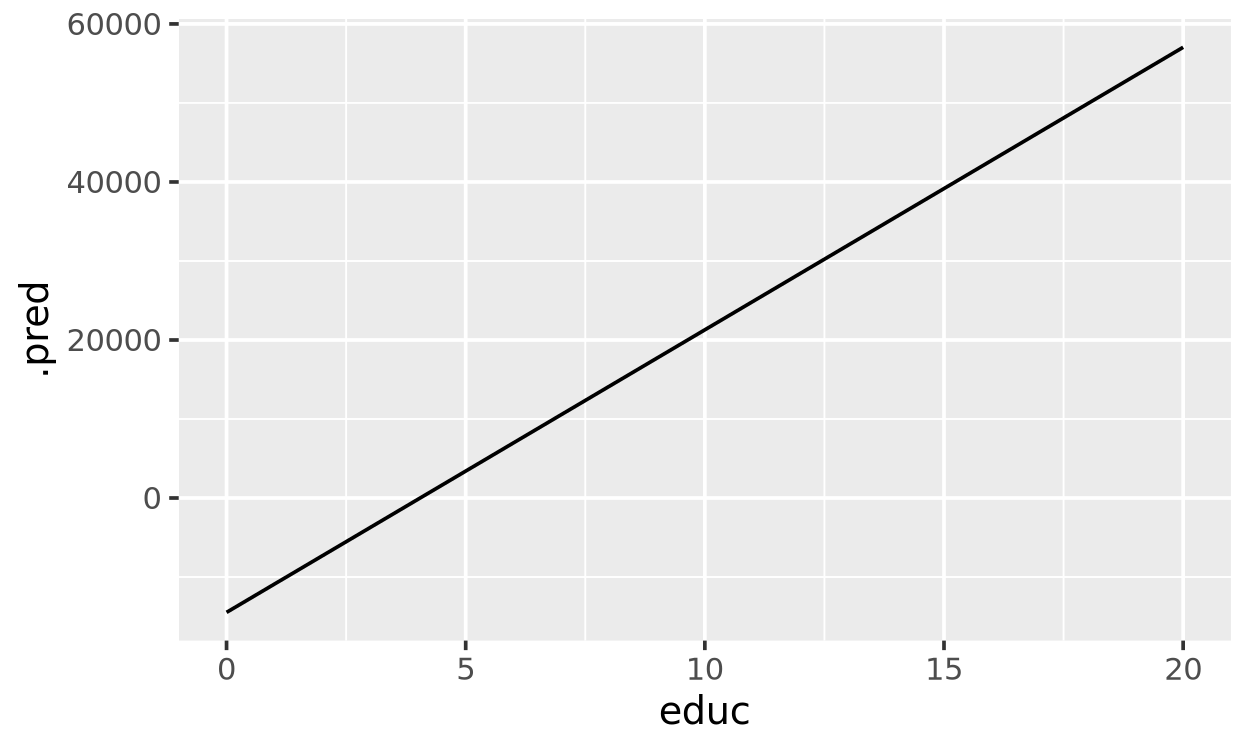

In [51]:
predict(mod_fit, gss) |> bind_cols(gss) |> ggplot(aes(x = educ, y = .pred)) + geom_line()

In [60]:
gss2 = gss |> mutate(educ_squared = educ^2) 

mod_fit = mod |> fit(realinc ~ educ + educ_squared, data =  gss2) # "fit" means find the optimal parameter values
                                                  # formula syntax

mod_fit

parsnip model object


Call:
stats::lm(formula = realinc ~ educ + educ_squared, data = data)

Coefficients:
 (Intercept)          educ  educ_squared  
     10802.2        -729.6         171.4  


Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”
Warning message:
“Removed 286 rows containing missing values or values outside the scale range (`geom_line()`).”


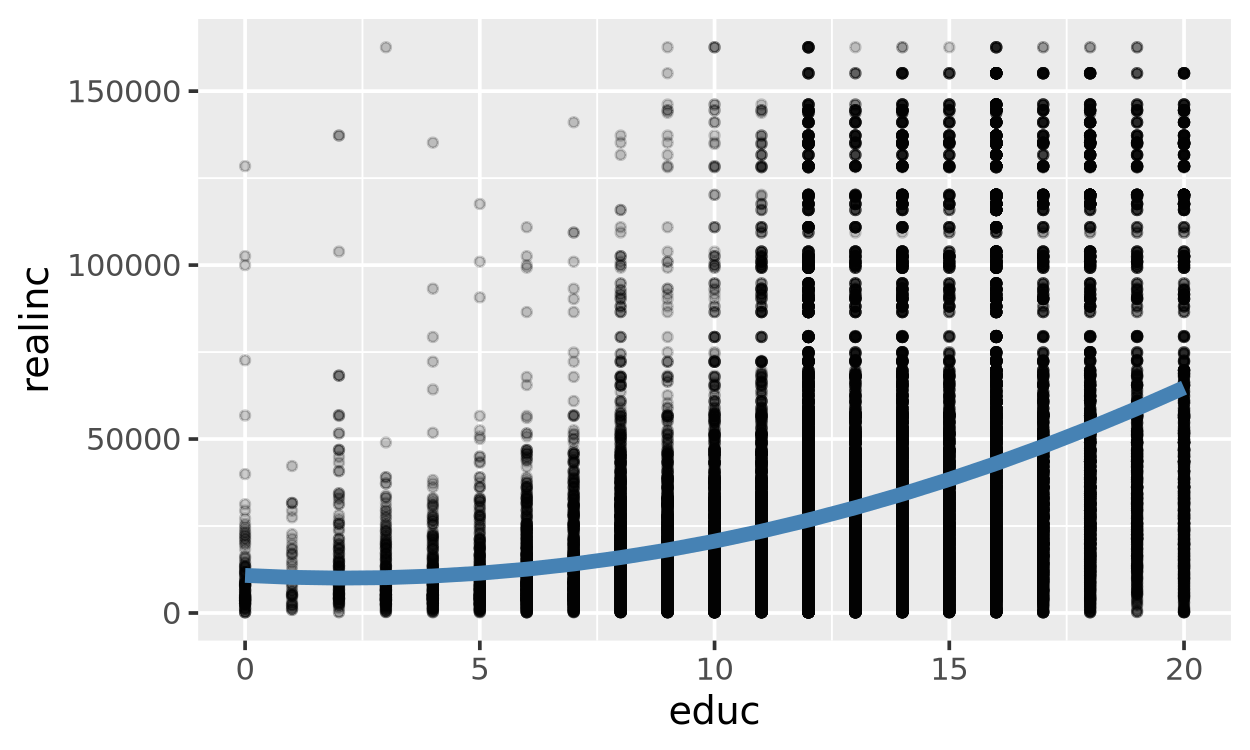

In [61]:
predict(mod_fit, gss2) |> bind_cols(gss) |>
ggplot(aes(x = educ, y = realinc)) + 
    geom_point(alpha = .2, size =1) +
    geom_line(aes(y = .pred), color = 'steelblue', linewidth = 2)

In [62]:
# no single value for the marginal effect of education on income